Telemetry frameworks like `mlflow` really shine when developing complex ML models with wide scopes of architectural designs, hyperparameter options, and training/optimization choices. This nb demonstrates how `mlflow` facilitates the development of such a model using a simple CNN for image recognition.

## Set Up `mlflow`

In [1]:
import mlflow

# point the client at the local mlflow server
# if you don't do this, mlflow will log to a local directory called mlruns
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# set a new experiment
mlflow.set_experiment("mlflow-fashion-mnist-cnn")

# inspect the experiment
experiment = mlflow.get_experiment_by_name("mlflow-fashion-mnist-cnn")
print(f"Experiment_id: {experiment.experiment_id}")
print(f"Artifact Location: {experiment.artifact_location}")
print(f"Tags: {experiment.tags}")
print(f"Lifecycle_stage: {experiment.lifecycle_stage}")

Experiment_id: 3
Artifact Location: mlflow-artifacts:/3
Tags: {}
Lifecycle_stage: active


## Prep Data

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) is 70,000 28x28 grayscale images of clothing in 10 classes (60,000 train, 10,000 test). It is a drop-in replacement for MNIST that is harder to saturate, so architecture and hyperparameter changes show up in the metrics.

In [2]:
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)

# the repo-level data/ dir is gitignored; downloads happen once and are reused
DATA_DIR = Path.cwd().parent / "data"

# standard Fashion-MNIST channel mean and std
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])

train_ds = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=transform)

BATCH_SIZE = 128
# num_workers=0 avoids multiprocessing spawn issues for notebooks on Windows
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds):,} images | Test: {len(test_ds):,} images")
print(f"Image shape: {tuple(train_ds[0][0].shape)}")
print(f"Classes: {train_ds.classes}")

Train: 60,000 images | Test: 10,000 images
Image shape: (1, 28, 28)
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


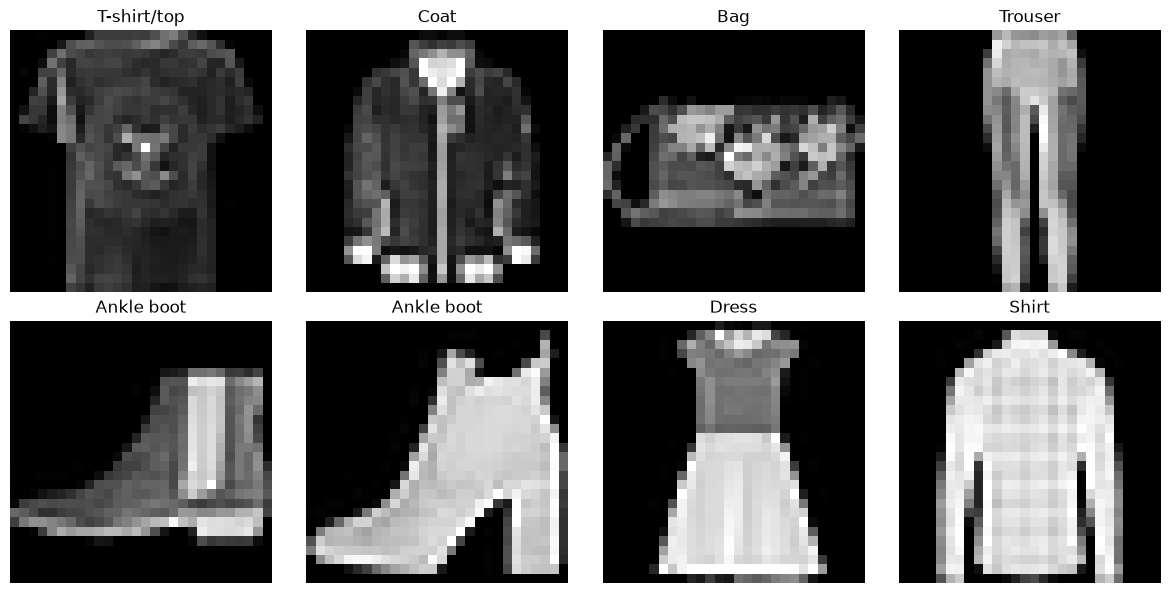

In [3]:
import numpy as np

import matplotlib.pyplot as plt

# pick a few random images from the training set
sample_indices = np.random.choice(len(train_ds), size=8, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, idx in zip(axes.flat, sample_indices):
    image, label = train_ds[idx]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(train_ds.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Define the Model

A light CNN: two conv/pool blocks followed by a single linear classifier. Architecture choices (channel widths, dropout) are constructor arguments, so each is a natural hyperparameter to track with `mlflow`. Training lives outside the model, in a function we define below.

In [4]:
from __future__ import annotations

from torch import nn


class FashionCNN(nn.Module):
    """Classify 28x28 grayscale images with two conv blocks and a linear head."""

    def __init__(self, conv1_channels: int = 16, conv2_channels: int = 32, dropout: float = 0.25) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, conv1_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16x28x28 -> 16x14x14
            nn.Conv2d(conv1_channels, conv2_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32x14x14 -> 32x7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),         # flatten 32x7x7 -> 1568
            nn.Dropout(dropout),
            nn.Linear(conv2_channels * 7 * 7, 10),  # 10 classes for Fashion-MNIST; 1568 -> 10
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Return class logits for a batch of images."""
        return self.classifier(self.features(x))

In [5]:
# sanity check: instantiate the model and push one batch through it
model = FashionCNN()
n_params = sum(p.numel() for p in model.parameters())

x, y = next(iter(train_loader))
print(model)
print(f"\nParameters: {n_params:,}")
print(f"Batch in: {tuple(x.shape)} -> logits out: {tuple(model(x).shape)}")

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=1568, out_features=10, bias=True)
  )
)

Parameters: 20,490
Batch in: (128, 1, 28, 28) -> logits out: (128, 10)


## Train and log

`train_and_log` takes any `model` and `optimizer` and handles training and logging together. Everything it logs goes into a single `mlflow` **run**, so the configuration, the learning curves, the data lineage, and the trained model end up attached to one record. Because the model and optimizer are arguments, trying a different architecture or optimizer is a one-line change at the call site, and the function records whatever it was given.

| Step | `mlflow` call | What it gives you |
|---|---|---|
| Open the run | `start_run` | One record per training attempt. Everything logged inside the `with` block belongs to it. |
| Track hardware | `start_run(log_system_metrics=True)` | CPU, memory, disk, and network usage (plus GPU if present) sampled in the background as `system/*` metrics. Shown on the run's **System metrics** tab. |
| Label it | `set_tags` | Free-form labels to search and filter runs later. |
| Record the configuration | `log_params` | Optimizer settings (read from the optimizer itself), training settings, and any model settings the caller passes. These are what you compare across runs. |
| Record the model structure | `log_text` | The printed layer summary, stored as a file artifact. |
| Record the data | `log_input` | A reference to the train and eval datasets (name, schema, digest). The images are not copied. |
| Track training | `log_metrics(..., step=epoch)` | One point per epoch, which the UI plots as a learning curve. |
| Record cost | `log_metric` | A single summary number (training time). |
| Save the model | `mlflow.pytorch.log_model` | The trained network plus its input/output signature and an example input, so it can be reloaded or served later. |

System metrics need `psutil` (already installed). GPU metrics additionally need `nvidia-ml-py`, which this CPU-only environment doesn't have.

In [6]:
import time

from mlflow.models import infer_signature
from torch.optim import Optimizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# system metrics (CPU, memory, disk, network, and GPU if present) are sampled by a background
# thread while a run is active; sample every 2s instead of the 10s default so short runs get a curve
mlflow.set_system_metrics_sampling_interval(2)


@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, device: str = DEVICE) -> dict[str, float]:
    """Compute mean cross-entropy loss and accuracy over a data loader."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += nn.functional.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return {"loss": total_loss / n, "accuracy": correct / n}


def train_and_log(
    model: nn.Module,
    optimizer: Optimizer,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int = 5,
    run_name: str | None = None,
    params: dict | None = None,
    tags: dict[str, str] | None = None,
    device: str = DEVICE,
) -> str:
    """Train `model` with cross-entropy loss and log the whole run to MLflow.

    Args:
        params: Extra settings to record, such as the model's constructor arguments.
        tags: Extra tags to attach to the run.

    The loaders' datasets must expose torchvision-style `.data` and `.targets`.
    """
    # start_run opens a run; everything logged in this block is attached to it,
    # and the run is marked FINISHED (or FAILED if an exception escapes) on exit.
    # log_system_metrics=True also records hardware usage (system/* metrics) for the run's duration
    with mlflow.start_run(run_name=run_name, log_system_metrics=True) as run:
        # tags are free-form labels, useful for searching and filtering runs later
        mlflow.set_tags({"framework": "pytorch", "model_class": type(model).__name__, **(tags or {})})

        # params are the run's configuration: logged once, compared across runs.
        # Optimizer settings are read from the optimizer, so they can't drift from what ran.
        mlflow.log_params(
            {
                "epochs": epochs,
                "batch_size": train_loader.batch_size,
                "device": device,
                "loss_fn": "cross_entropy",
                "n_parameters": sum(p.numel() for p in model.parameters()),
                "optimizer": type(optimizer).__name__,
                **{f"optimizer_{k}": v for k, v in optimizer.defaults.items()},
                **(params or {}),
            }
        )

        # log_text stores a string as a file artifact; here, the layer-by-layer structure
        mlflow.log_text(str(model), "model_summary.txt")

        # log_input records which data the run used: a name, schema, and digest, not the images
        train_data = mlflow.data.from_numpy(
            train_loader.dataset.data.numpy(),
            targets=train_loader.dataset.targets.numpy(),
            name="fashion-mnist-train",
        )
        eval_data = mlflow.data.from_numpy(
            val_loader.dataset.data.numpy(),
            targets=val_loader.dataset.targets.numpy(),
            name="fashion-mnist-eval",
        )
        mlflow.log_input(train_data, context="training")
        mlflow.log_input(eval_data, context="evaluation")

        model.to(device)
        start = time.perf_counter()
        for epoch in range(1, epochs + 1):
            model.train()
            running_loss, n = 0.0, 0
            for x, y in train_loader:
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                loss = nn.functional.cross_entropy(model(x), y)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * len(y)
                n += len(y)

            val = evaluate(model, val_loader, device)
            metrics = {
                "train_loss": running_loss / n,
                "val_loss": val["loss"],
                "val_accuracy": val["accuracy"],
            }
            print(f"epoch {epoch}/{epochs} | " + " | ".join(f"{k}: {v:.4f}" for k, v in metrics.items()))

            # metrics logged with step=epoch become learning curves in the UI
            mlflow.log_metrics(metrics, step=epoch)

        # a single-value metric summarizing the run
        mlflow.log_metric("training_seconds", time.perf_counter() - start)

        # log_model saves the network with a signature (input/output shapes and types)
        # and an example input, so the model can be reloaded or served later
        model.to("cpu").eval()
        sample = next(iter(val_loader))[0][:5].numpy()
        with torch.no_grad():
            logits = model(torch.from_numpy(sample)).numpy()
        mlflow.pytorch.log_model(
            model,
            name="model",
            signature=infer_signature(sample, logits),
            input_example=sample,
        )
    return run.info.run_id

Test run

In [7]:
model_config = {"conv1_channels": 16, "conv2_channels": 32, "dropout": 0.25}

torch.manual_seed(42)  # fix the initial weights so reruns are comparable
model = FashionCNN(**model_config)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

base_run_id = train_and_log(
    model,
    optimizer,
    train_loader,
    test_loader,
    epochs=5,
    run_name="base_cnn",
    params={**model_config, "seed": 42},
    tags={"stage": "baseline"},
)
print(f"\nbase run: {base_run_id}")

2026/11/05 08:40:43 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/05 08:40:43 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


epoch 1/5 | train_loss: 0.5465 | val_loss: 0.3909 | val_accuracy: 0.8649
epoch 2/5 | train_loss: 0.3730 | val_loss: 0.3484 | val_accuracy: 0.8776
epoch 3/5 | train_loss: 0.3291 | val_loss: 0.3134 | val_accuracy: 0.8890
epoch 4/5 | train_loss: 0.3069 | val_loss: 0.3090 | val_accuracy: 0.8895
epoch 5/5 | train_loss: 0.2890 | val_loss: 0.2886 | val_accuracy: 0.8958


2026/11/05 08:42:43 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/05 08:42:44 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/05 08:42:44 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run base_cnn at: http://127.0.0.1:5000/#/experiments/3/runs/8178806660ba45b38b0dbc0071ee3b04
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

base run: 8178806660ba45b38b0dbc0071ee3b04


## Compare model designs

Because `train_and_log` records every run the same way, trying a new design is just a new `model` and `optimizer` argument. Below we train four variants that differ in width and dropout, then pull all five runs (these four plus the base model) back out of `mlflow` into a DataFrame.

Each design trains for the same number of epochs as the base model, so expect this cell to take several minutes on CPU. Lower `EPOCHS` for a faster (but not base-comparable) pass.

In [8]:
import pandas as pd

EPOCHS = 5  # matches the base run so the comparison is like-for-like

designs = {
    "tiny": {"conv1_channels": 4, "conv2_channels": 8, "dropout": 0.0},
    "narrow": {"conv1_channels": 8, "conv2_channels": 16, "dropout": 0.25},
    "wide": {"conv1_channels": 32, "conv2_channels": 64, "dropout": 0.25},
    "wide_high_dropout": {"conv1_channels": 32, "conv2_channels": 64, "dropout": 0.5},
}

# one run per design, each logged by the same function; start from the base run's id
run_ids = {"base_cnn": base_run_id}
for name, cfg in designs.items():
    torch.manual_seed(42)
    model = FashionCNN(**cfg)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    run_ids[name] = train_and_log(
        model,
        optimizer,
        train_loader,
        test_loader,
        epochs=EPOCHS,
        run_name=name,
        params={**cfg, "seed": 42},
        tags={"stage": "design-comparison"},
    )

# read the runs back from the tracking server; metrics hold each run's final-epoch value
ids = ", ".join(f"'{run_id}'" for run_id in run_ids.values())
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"attributes.run_id IN ({ids})",
).set_index("tags.mlflow.runName")

columns = [
    "params.n_parameters",
    "metrics.train_loss",
    "metrics.val_loss",
    "metrics.val_accuracy",
    "metrics.training_seconds",
]
comparison = runs[columns].rename(columns=lambda c: c.split(".", 1)[1]).rename_axis("design").astype(float)
comparison["n_parameters"] = comparison["n_parameters"].astype(int)
comparison.sort_values("val_accuracy", ascending=False).round(4)

2026/11/05 08:42:44 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/05 08:42:44 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


epoch 1/5 | train_loss: 0.7299 | val_loss: 0.5065 | val_accuracy: 0.8187
epoch 2/5 | train_loss: 0.4402 | val_loss: 0.4280 | val_accuracy: 0.8462
epoch 3/5 | train_loss: 0.3896 | val_loss: 0.4198 | val_accuracy: 0.8490
epoch 4/5 | train_loss: 0.3650 | val_loss: 0.3702 | val_accuracy: 0.8693
epoch 5/5 | train_loss: 0.3468 | val_loss: 0.3612 | val_accuracy: 0.8711


2026/11/05 08:44:22 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/05 08:44:23 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/05 08:44:23 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/05 08:44:23 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/05 08:44:23 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run tiny at: http://127.0.0.1:5000/#/experiments/3/runs/bb9b117c56ef4755902cd04352eb3092
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
epoch 1/5 | train_loss: 0.6465 | val_loss: 0.4469 | val_accuracy: 0.8378
epoch 2/5 | train_loss: 0.4301 | val_loss: 0.3930 | val_accuracy: 0.8589
epoch 3/5 | train_loss: 0.3900 | val_loss: 0.3660 | val_accuracy: 0.8684
epoch 4/5 | train_loss: 0.3677 | val_loss: 0.3534 | val_accuracy: 0.8753
epoch 5/5 | train_loss: 0.3520 | val_loss: 0.3381 | val_accuracy: 0.8767


2026/11/05 08:46:06 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


... (5 outputs left out)

2026/11/05 08:52:17 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/05 08:52:17 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/05 08:52:17 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run wide_high_dropout at: http://127.0.0.1:5000/#/experiments/3/runs/20572391a57843c28952eb0fda290515
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


,n_parameters,train_loss,val_loss,val_accuracy,training_seconds
design,,,,,
wide,50186,0.2348,0.2567,0.9069,170.0516
wide_high_dropout,50186,0.2664,0.2724,0.9040,185.0019
base_cnn,20490,0.2890,0.2886,0.8958,113.0247
narrow,9098,0.3520,0.3381,0.8767,96.2179
tiny,4266,0.3468,0.3612,0.8711,90.2165


### Comments
Please look at the server UI after running this. Particularly, go to `Experiments/mlflow-fashion-mnist-cnn/runs` and select "Chart View". Super powerful and informative comparisons there.